# Session 1 - Mining a toxicity dataset

**AI in Quantitative Biology - practical 1 of 3 (90 min)**

How toxic is a chemical to fish? Testing every new compound on animals is slow, expensive and
ethically costly, so regulators (e.g. EU REACH) accept **QSAR** models: *Quantitative
Structure-Activity Relationships*, i.e. models that predict a biological effect from numbers
computed on the molecular structure.

Today we take a real dataset, **look at it** before modelling, and then fit and compare a few
simple regression models.

| Part | Topic | Time |
|---|---|---|
| 1 | Meet the data | 15 min |
| 2 | Correlations: what goes with toxicity? | 10 min |
| 3 | An unsupervised look: PCA | 5 min |
| 4 | A first model: linear regression | 20 min |
| 5 | Non-linear models and cross-validation | 25 min |
| 6 | What did the model learn? | 10 min |
| 7 | Your turn: water fleas | homework |

✏️ marks exercises and ❓ questions to discuss with your neighbour: try them yourself first, the solution follows right after.

## Setup

Everything runs on a laptop CPU in a few minutes; no GPU needed. The notebook expects the
`data/` folder of the course (it looks for it in the current folder and the folders above).
On Google Colab, upload the `data/` folder to your Drive in `MyDrive/AI_QBio/data` and run the
cell below: it mounts the Drive and finds it there.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)

import os
from pathlib import Path

def find_data_dir():
    """$QBIO_DATA if set, else a `data/` folder here or above, else Google Drive on Colab."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "qsar_fish_toxicity.csv").exists():
            return p / "data"
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        return Path("/content/drive/MyDrive/AI_QBio/data")
    raise FileNotFoundError("Cannot find the data/ folder: set QBIO_DATA to its path")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

FISH_COLUMNS = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]

def load_fish():
    """Fathead minnow 96 h LC50 for 908 chemicals (UCI QSAR fish toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_fish_toxicity.csv", sep=";", header=None, names=FISH_COLUMNS)

AQUATIC_COLUMNS = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040", "LC50"]

def load_aquatic():
    """Daphnia magna 48 h LC50 for 546 chemicals (UCI QSAR aquatic toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_aquatic_toxicity.csv", sep=";", header=None, names=AQUATIC_COLUMNS)

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


## Part 1 - Meet the data

The dataset (Cassotti et al. 2015, UCI repository) lists **908 chemicals** tested on the fathead
minnow (*Pimephales promelas*), a standard test fish. For each chemical:

* **`LC50`**: the concentration that kills 50% of the fish in 96 hours, given as
  $-\log_{10}(\text{mol/L})$. **Larger = more toxic** (less substance needed).
* six **molecular descriptors** computed from the structure:

| descriptor | meaning, roughly |
|---|---|
| `CIC0` | information content index - how "complex"/heterogeneous the molecule is |
| `SM1_Dz` | spectral moment weighted by atomic number - grows with heavy atoms (Cl, Br, I...) |
| `GATS1i` | autocorrelation of ionisation potential between bonded atoms |
| `NdsCH` | number of `=CH-` atoms (unsaturated carbons) |
| `NdssC` | number of `=C<` atoms (unsaturated carbons) |
| `MLOGP` | predicted octanol/water partition coefficient - **lipophilicity** ("how fatty") |

In [2]:
fish = load_fish()
fish.head()

,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
0,3.260,0.829,1.676,0,1,1.453,3.770
1,2.189,0.580,0.863,0,0,1.348,3.115
2,2.125,0.638,0.831,0,0,1.348,3.531
3,3.027,0.331,1.472,1,0,1.807,3.510
4,2.094,0.827,0.860,0,0,1.886,5.390


In [3]:
fish.describe()

,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
count,908.000,908.000,908.000,908.000,908.000,908.000,908.000
mean,2.898,0.628,1.294,0.229,0.486,2.109,4.064
std,0.756,0.428,0.394,0.605,0.861,1.433,1.456
min,0.667,0.000,0.396,0.000,0.000,-2.884,0.053
25%,2.347,0.223,0.951,0.000,0.000,1.209,3.152
50%,2.934,0.570,1.240,0.000,0.000,2.127,3.987
75%,3.407,0.893,1.562,0.000,1.000,3.105,4.907
max,5.926,2.171,2.920,4.000,6.000,6.515,9.612


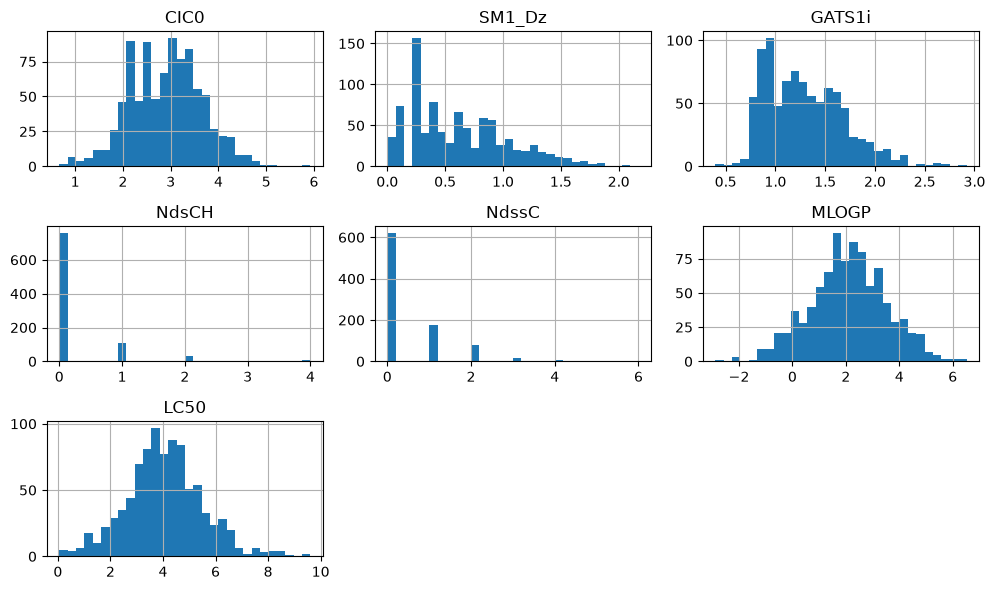

In [4]:
fish.hist(bins=30, figsize=(10, 6))
plt.tight_layout()

✏️ **Exercise 1.1.** Answer with one line of pandas each:
1. Which descriptors are **counts** (only integer values)? *Hint:* `fish[col].nunique()` or look at the histograms.
2. What is the LC50 of the **most toxic** chemical, and in which row is it? *Hint:* `.max()`, `.idxmax()`.
3. How many chemicals have an LC50 above 6 (i.e. lethal below 1 µmol/L)?

In [5]:
# 1. counts have few distinct values
print(fish.nunique())
# 2.
print("max LC50:", fish["LC50"].max(), "in row", fish["LC50"].idxmax())
# 3.
print((fish["LC50"] > 6).sum(), "chemicals with LC50 > 6")

CIC0      502
SM1_Dz    186
GATS1i    557
NdsCH       5
NdssC       7
MLOGP     559
LC50      827
dtype: int64
max LC50: 9.612 in row 259
87 chemicals with LC50 > 6


❓ An LC50 of 6 means $10^{-6}$ mol/L. What is the difference in lethal concentration between a
chemical with LC50 = 3 and one with LC50 = 6?

**Answer.** The scale is logarithmic: 3 units = a factor of $10^3$ = **1000 times** less substance is
needed. NdsCH and NdssC are the counts. The most toxic chemical has LC50 ≈ 9.6.

## Part 2 - Correlations: what goes with toxicity?

The Pearson correlation $r$ measures how well two variables follow a straight line ($-1$ to $+1$).

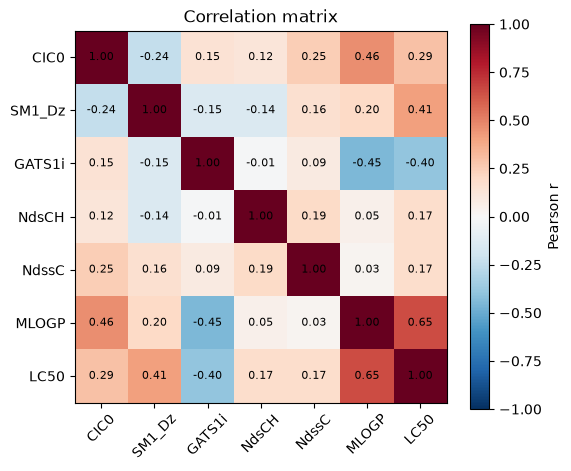

In [6]:
corr = fish.corr()
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Pearson r")
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation matrix");

✏️ **Exercise 2.1.** Sort the descriptors by their correlation with `LC50`, then make a scatter
plot of the most correlated one against `LC50`.

MLOGP     0.652
SM1_Dz    0.411
CIC0      0.292
NdssC     0.172
NdsCH     0.172
GATS1i   -0.398
Name: LC50, dtype: float64


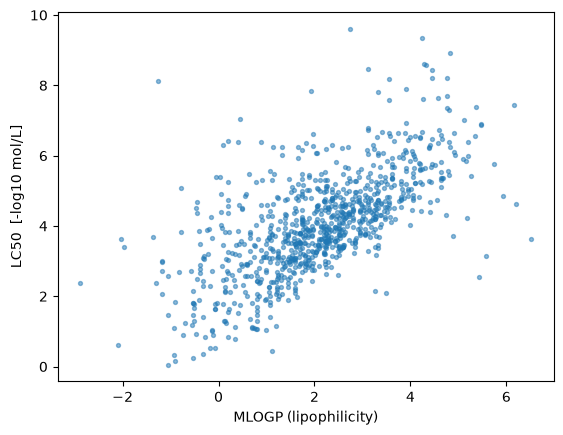

In [7]:
print(corr["LC50"].drop("LC50").sort_values(ascending=False))

plt.scatter(fish["MLOGP"], fish["LC50"], s=8, alpha=0.5)
plt.xlabel("MLOGP (lipophilicity)")
plt.ylabel("LC50  [-log10 mol/L]");

❓ Lipophilicity (`MLOGP`) is the strongest single predictor. Can you think of a biological reason?

**Answer.** Most industrial chemicals act by **baseline toxicity ("narcosis")**: they dissolve in
cell membranes and disturb them non-specifically. The more lipophilic the molecule, the more it
accumulates in membranes (and crosses the gills), so the less of it is needed to kill.
Chemicals with a *specific* mode of action (e.g. pesticides hitting an enzyme) are more toxic than
their logP predicts - they are the points above the main cloud.

## Part 3 - An unsupervised look: PCA

With 6 descriptors we cannot plot all the data at once. **Principal Component Analysis** finds the
directions along which the data vary the most and lets us draw a 2D "map" of the chemicals.
We do not give it LC50: we only colour the points by toxicity afterwards.

Descriptors have very different units, so we first **standardise** them (mean 0, std 1).

variance explained by PC1, PC2: [0.274 0.245]


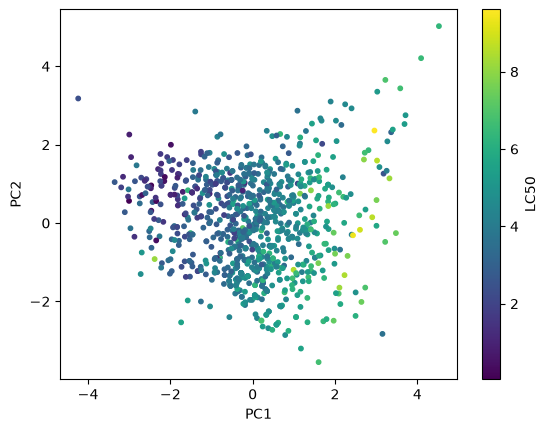

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = fish.drop(columns="LC50")
y = fish["LC50"]

Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=2).fit(Xs)
Z = pca.transform(Xs)
print("variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3))

plt.scatter(Z[:, 0], Z[:, 1], c=y, cmap="viridis", s=10)
plt.colorbar(label="LC50")
plt.xlabel("PC1"); plt.ylabel("PC2");

In [9]:
# which descriptors make up each component ("loadings")?
pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])

,PC1,PC2
CIC0,0.506,0.471
SM1_Dz,0.137,-0.479
GATS1i,-0.366,0.533
NdsCH,0.202,0.358
NdssC,0.267,0.315
MLOGP,0.692,-0.194


❓ Is toxicity organised along the map? Which descriptors dominate PC1?

**Answer.** There is a colour gradient (toxic chemicals mostly on one side), but it is far from a
clean separation: two components capture only about half of the variance (27% + 25%) and toxicity
is only partly aligned with them. PC1 is mostly lipophilicity and complexity (`MLOGP`, `CIC0`);
PC2 contrasts `GATS1i`/`CIC0` with `SM1_Dz`. PCA is a good first look, not a predictor.

## Part 4 - A first model: linear regression

To know whether a model is any good we must test it on chemicals it has **not seen**. We keep 25%
of the data aside as a **test set**.

Two metrics:
* **RMSE** (root mean squared error), in LC50 units: the typical size of an error.
* **R²**: fraction of the variance explained. 0 = no better than always predicting the mean, 1 = perfect.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RNG)
print(len(X_train), "training chemicals,", len(X_test), "test chemicals")

# the dumbest possible model: always predict the training mean
baseline = np.full(len(y_test), y_train.mean())
print(f"baseline  RMSE = {root_mean_squared_error(y_test, baseline):.3f}")

681 training chemicals, 227 test chemicals
baseline  RMSE = 1.399


LC50 = 2.57 + 0.70 * MLOGP
MLOGP only:  RMSE = 1.200   R2 = 0.264


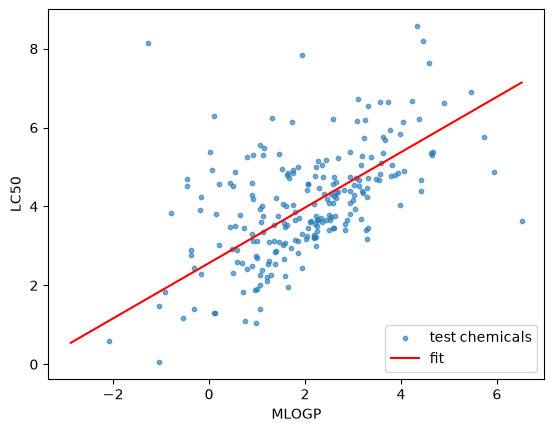

In [11]:
lr1 = LinearRegression().fit(X_train[["MLOGP"]], y_train)
pred = lr1.predict(X_test[["MLOGP"]])
print(f"LC50 = {lr1.intercept_:.2f} + {lr1.coef_[0]:.2f} * MLOGP")
print(f"MLOGP only:  RMSE = {root_mean_squared_error(y_test, pred):.3f}   R2 = {r2_score(y_test, pred):.3f}")

xs = np.linspace(X["MLOGP"].min(), X["MLOGP"].max(), 50)
plt.scatter(X_test["MLOGP"], y_test, s=10, alpha=0.6, label="test chemicals")
plt.plot(xs, lr1.predict(pd.DataFrame({"MLOGP": xs})), "r", label="fit")
plt.xlabel("MLOGP"); plt.ylabel("LC50"); plt.legend();

### What does "fitting" mean? The loss landscape

`LinearRegression` chooses the intercept $a$ and slope $b$ that minimise the **loss**: the mean
squared error (MSE) on the *training* chemicals,
$\text{MSE}(a, b) = \frac{1}{n}\sum_i \big(y_i - (a + b\,x_i)\big)^2$.
Each pair $(a, b)$ has its own loss, so we can draw the loss as a map, like a landscape with a valley.

Linear regression finds the bottom of the valley with a formula. Neural networks (session 2) have no
such formula. They start somewhere and walk **downhill** in small steps, each step following the
slope of the loss (**gradient descent**). Below we do both and check that they end up at the same point.

gradient descent: a = 2.566, b = 0.702
LinearRegression: a = 2.567, b = 0.702


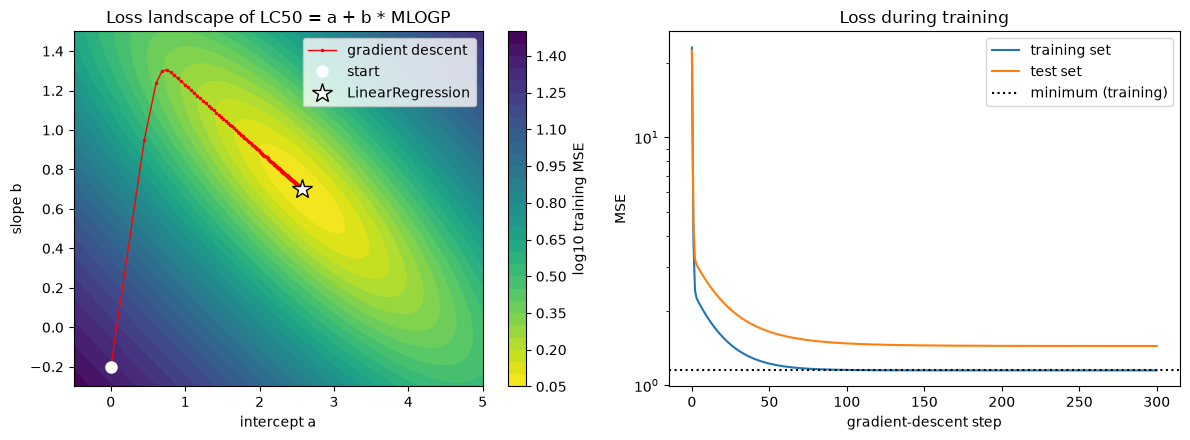

In [12]:
x_tr, y_tr = X_train["MLOGP"].values, y_train.values
x_te, y_te = X_test["MLOGP"].values, y_test.values

def mse(a, b, x=x_tr, y=y_tr):
    return np.mean((y - (a + b * x)) ** 2)

# the loss on a grid of (intercept, slope) values
a_grid, b_grid = np.linspace(-0.5, 5, 150), np.linspace(-0.3, 1.5, 150)
L = np.array([[mse(a, b) for a in a_grid] for b in b_grid])

# gradient descent: start from a bad guess, step against the gradient of the MSE
a, b, lr = 0.0, -0.2, 0.05                     # lr = learning rate (step size)
path, train_loss, test_loss = [(a, b)], [mse(a, b)], [mse(a, b, x_te, y_te)]
for step in range(300):
    err = (a + b * x_tr) - y_tr
    a -= lr * 2 * err.mean()                   # dMSE/da
    b -= lr * 2 * (err * x_tr).mean()          # dMSE/db
    path.append((a, b))
    train_loss.append(mse(a, b)); test_loss.append(mse(a, b, x_te, y_te))
path = np.array(path)
print(f"gradient descent: a = {a:.3f}, b = {b:.3f}")
print(f"LinearRegression: a = {lr1.intercept_:.3f}, b = {lr1.coef_[0]:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
cs = ax1.contourf(a_grid, b_grid, np.log10(L), levels=30, cmap="viridis_r")
fig.colorbar(cs, ax=ax1, label="log10 training MSE")
ax1.plot(path[:, 0], path[:, 1], "r.-", ms=3, lw=1, label="gradient descent")
ax1.plot(*path[0], "wo", ms=8, label="start")
ax1.plot(lr1.intercept_, lr1.coef_[0], "w*", ms=15, mec="k", label="LinearRegression")
ax1.set_xlabel("intercept a"); ax1.set_ylabel("slope b"); ax1.legend(loc="upper right")
ax1.set_title("Loss landscape of LC50 = a + b * MLOGP")

ax2.plot(train_loss, label="training set")
ax2.plot(test_loss, label="test set")
ax2.axhline(mse(lr1.intercept_, lr1.coef_[0]), color="k", ls=":", label="minimum (training)")
ax2.set_yscale("log"); ax2.set_xlabel("gradient-descent step"); ax2.set_ylabel("MSE")
ax2.set_title("Loss during training"); ax2.legend()
plt.tight_layout()

❓ The valley is long, narrow and **tilted**. Why? Gradient descent drops quickly into the valley and
then crawls along it: what does that tell you? Try `lr = 0.15`: what happens?

**Answer.** The two parameters trade off against each other. All MLOGP values are around 2, so a
steeper slope can be almost compensated by a lower intercept, and many $(a, b)$ pairs along that
diagonal fit almost equally well. Gradient descent takes big steps where the walls are steep and tiny
steps along the flat floor of the valley, so most of the 300 steps are spent creeping along it.
With `lr = 0.15` the steps overshoot from one wall to the other and the loss **explodes**: here any
learning rate above ≈ 0.14 diverges. If MLOGP is centred (mean 0) the valley becomes round and
gradient descent goes straight to the minimum. This is one reason we standardise the inputs of
neural networks. Note also that the test loss follows the training loss down: a straight line has
too few parameters to overfit. In session 2 we will see a network whose two curves separate.

✏️ **Exercise 4.1.** Fit a `LinearRegression` on **all six** descriptors (`X_train`) and report RMSE and
R² on the test set. Does it beat MLOGP alone?

In [13]:
lr_all = LinearRegression().fit(X_train, y_train)
pred_all = lr_all.predict(X_test)
print(f"all six:  RMSE = {root_mean_squared_error(y_test, pred_all):.3f}   R2 = {r2_score(y_test, pred_all):.3f}")

all six:  RMSE = 1.045   R2 = 0.442


Raw coefficients cannot be compared with each other (different units). Fitting on standardised
descriptors makes each coefficient mean "change in LC50 per one standard deviation of the descriptor".

GATS1i   -0.273
NdssC     0.030
NdsCH     0.254
CIC0      0.289
SM1_Dz    0.544
MLOGP     0.625
dtype: float64


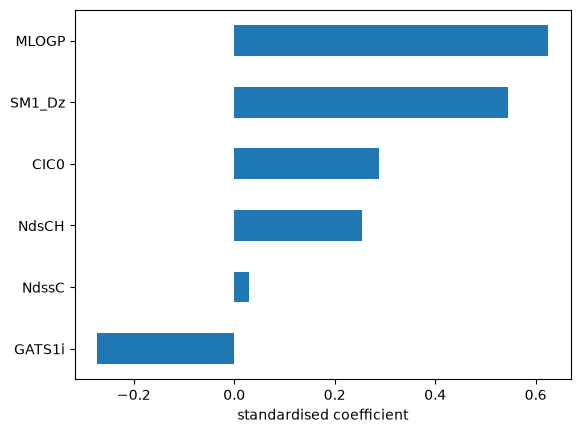

In [14]:
from sklearn.pipeline import make_pipeline

lr_std = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
coefs = pd.Series(lr_std[-1].coef_, index=X.columns).sort_values()
print(coefs)
coefs.plot.barh()
plt.xlabel("standardised coefficient");

❓ Which descriptors increase predicted toxicity, which decrease it?

**Answer.** `MLOGP` has by far the largest positive effect, followed by `SM1_Dz` (heavy atoms);
`GATS1i` has a negative coefficient. Careful: with correlated descriptors, coefficients share the
credit and individual values should not be over-interpreted.
On this test split R² rises from ≈ 0.26 (MLOGP alone) to ≈ 0.44 with all six descriptors. Keep these numbers in mind: in Part 5, cross-validation gives ≈ 0.41 and ≈ 0.56 - a single split of 227 chemicals is noisy.

## Part 5 - Non-linear models and cross-validation

A straight line may be too simple. Two classic non-linear models:

* **k-nearest neighbours (kNN)**: predict the average LC50 of the *k* most similar training
  chemicals. Similarity = distance in descriptor space, so scaling matters!
* **Random forest (RF)**: average of many decision trees, each trained on a random resample.

A single train/test split is noisy (it depends on which chemicals ended up in the test set).
**5-fold cross-validation** splits the data in 5 parts, uses each part once as test set, and
averages the 5 scores.

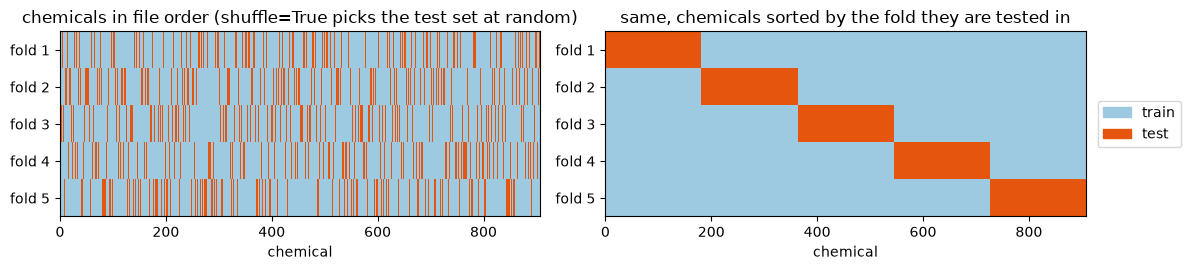

In [15]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RNG)

# which chemicals are in the test set of each fold?
fold_of = np.zeros(len(X), dtype=int)
role = np.zeros((cv.get_n_splits(), len(X)))           # 1 = test, 0 = train
for i, (train_idx, test_idx) in enumerate(cv.split(X)):
    role[i, test_idx] = 1
    fold_of[test_idx] = i

from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#9ecae1", "#e6550d"])           # train = blue, test = orange
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].imshow(role, aspect="auto", cmap=cmap, interpolation="nearest")
axes[0].set_title("chemicals in file order (shuffle=True picks the test set at random)")
axes[1].imshow(role[:, np.argsort(fold_of, kind="stable")], aspect="auto", cmap=cmap, interpolation="nearest")
axes[1].set_title("same, chemicals sorted by the fold they are tested in")
for ax in axes:
    ax.set_yticks(range(5), [f"fold {i + 1}" for i in range(5)])
    ax.set_xlabel("chemical")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#9ecae1", label="train"), Patch(color="#e6550d", label="test")],
               loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()

In [16]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "linear (MLOGP only)": ("MLOGP", LinearRegression()),
    "linear (all)":        (None, LinearRegression()),
    "kNN, k=10 (scaled)":  (None, make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10))),
    "random forest":       (None, RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)),
}

results, fold_scores = {}, {}
for name, (cols, model) in models.items():
    Xm = X[[cols]] if cols else X
    r2 = cross_val_score(model, Xm, y, cv=cv, scoring="r2")
    results[name] = (r2.mean(), r2.std())
    fold_scores[name] = r2
    print(f"{name:22s} R2 = {r2.mean():.3f} +/- {r2.std():.3f}")

linear (MLOGP only)    R2 = 0.408 +/- 0.053
linear (all)           R2 = 0.557 +/- 0.043
kNN, k=10 (scaled)     R2 = 0.619 +/- 0.023


random forest          R2 = 0.604 +/- 0.027


Each fold gives its own score. How different are they? And how unusual was the single split of
Part 4? Let us repeat that split with 200 different random seeds.

200 splits: R2 = 0.566 +/- 0.049, range 0.41 - 0.69
splits worse than ours: 1.5%


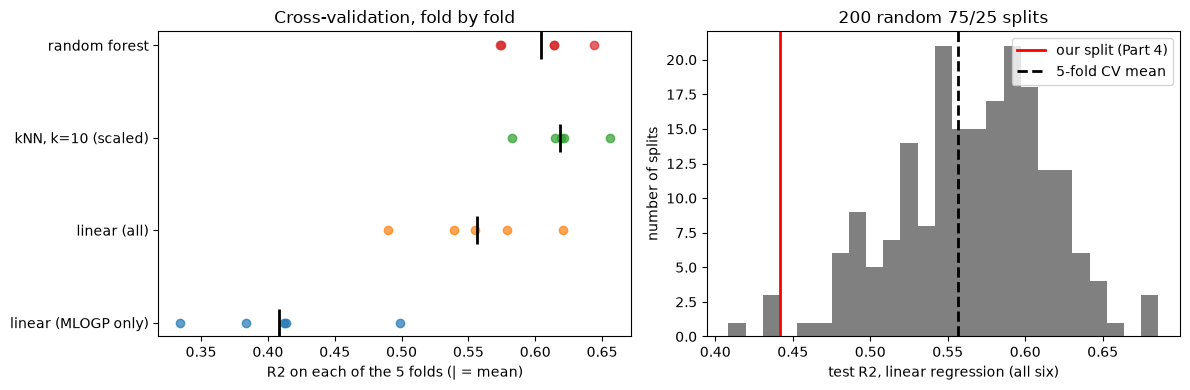

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for i, (name, r2) in enumerate(fold_scores.items()):
    ax1.plot(r2, np.full(5, i), "o", alpha=0.7)
    ax1.plot(r2.mean(), i, "k|", ms=20, mew=2)
ax1.set_yticks(range(len(fold_scores)), list(fold_scores))
ax1.set_xlabel("R2 on each of the 5 folds (| = mean)")
ax1.set_title("Cross-validation, fold by fold")

split_r2 = []
for seed in range(200):
    Xa_, Xb_, ya_, yb_ = train_test_split(X, y, test_size=0.25, random_state=seed)
    split_r2.append(r2_score(yb_, LinearRegression().fit(Xa_, ya_).predict(Xb_)))
split_r2 = np.array(split_r2)

ax2.hist(split_r2, bins=25, color="grey")
ax2.axvline(r2_score(y_test, pred_all), color="r", lw=2, label="our split (Part 4)")
ax2.axvline(fold_scores["linear (all)"].mean(), color="k", ls="--", lw=2, label="5-fold CV mean")
ax2.set_xlabel("test R2, linear regression (all six)"); ax2.set_ylabel("number of splits")
ax2.set_title("200 random 75/25 splits"); ax2.legend()
plt.tight_layout()
print(f"200 splits: R2 = {split_r2.mean():.3f} +/- {split_r2.std():.3f}, "
      f"range {split_r2.min():.2f} - {split_r2.max():.2f}")
print(f"splits worse than ours: {(split_r2 < r2_score(y_test, pred_all)).mean():.1%}")

❓ Was the split of Part 4 representative? Which number would you report for the linear model, and
can you say that the random forest is better than kNN?

**Answer.** No, it was unlucky: R² ≈ 0.44 falls in the worst 2% of the 200 random splits, which
average ≈ 0.57 ± 0.05. Whatever we conclude from one split of 227 chemicals can be off by
±0.1 in R². The cross-validated value (≈ 0.56) agrees with the average over many splits and is the
one to report. Fold to fold, R² varies by about ±0.05 for every model. That is as large as the
differences between kNN, RF and the linear model, so the ranking of the three non-trivial models is
*not* solid. Only "MLOGP alone is worse" is clear.

✏️ **Exercise 5.1.** Add kNN **without** the `StandardScaler` to the comparison. What happens, and why?

In [18]:
knn_raw = KNeighborsRegressor(n_neighbors=10)
r2 = cross_val_score(knn_raw, X, y, cv=cv, scoring="r2")
print(f"kNN unscaled R2 = {r2.mean():.3f}")

kNN unscaled R2 = 0.570


✏️ **Exercise 5.2.** Try a few values of `n_neighbors` for the scaled kNN (e.g. 1, 3, 10, 30, 100).
What happens with very small and very large *k*?

**Answer (5.1).** Without scaling R² drops (≈0.62 → 0.57): distances are dominated by the descriptors with
the largest numeric range, so the "nearest" chemicals are not really the most similar.
**Answer (5.2).** k=1 copies the single nearest chemical, including its noise (overfitting);
very large k averages over half the dataset and flattens everything towards the mean (underfitting).
The best is somewhere in between.

In [19]:
for k in [1, 3, 10, 30, 100]:
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    print(f"k={k:3d}  R2 = {cross_val_score(m, X, y, cv=cv, scoring='r2').mean():.3f}")

k=  1  R2 = 0.406
k=  3  R2 = 0.584
k= 10  R2 = 0.619
k= 30  R2 = 0.597
k=100  R2 = 0.520


The same question as a picture: the error on the **training** folds and on the **held-out** folds
as *k* changes. Small *k* = a flexible, "wiggly" model, large *k* = a smooth one.

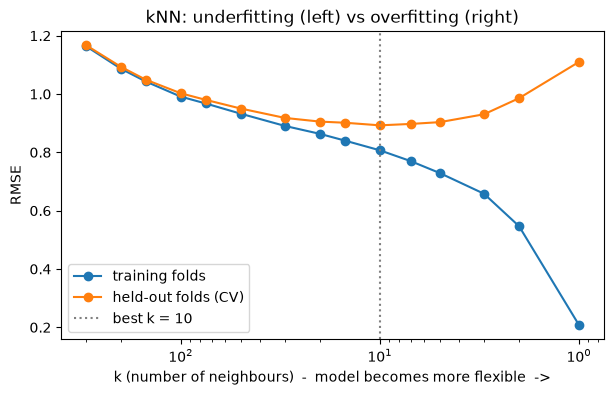

In [20]:
from sklearn.model_selection import cross_validate

ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300]
train_rmse, cv_rmse = [], []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    s = cross_validate(m, X, y, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True)
    train_rmse.append(-s["train_score"].mean())
    cv_rmse.append(-s["test_score"].mean())

best = ks[int(np.argmin(cv_rmse))]
plt.figure(figsize=(7, 4))
plt.plot(ks, train_rmse, "o-", label="training folds")
plt.plot(ks, cv_rmse, "o-", label="held-out folds (CV)")
plt.axvline(best, color="grey", ls=":", label=f"best k = {best}")
plt.xscale("log"); plt.gca().invert_xaxis()     # left: simple model, right: flexible model
plt.xlabel("k (number of neighbours)  -  model becomes more flexible  ->")
plt.ylabel("RMSE"); plt.legend()
plt.title("kNN: underfitting (left) vs overfitting (right)");

❓ Why is the training error at *k* = 1 not zero? Where does the gap between the two curves start
to open?

**Answer.** With *k* = 1 each training chemical is its own nearest neighbour, so the training error
should be zero. It is not, because some chemicals share **identical descriptors** but have different
LC50 (the model cannot tell them apart; the average gives the remaining error). On the left
(*k* ≥ 100) both errors are high and almost equal: underfitting. Going right, the training error keeps
falling, but the held-out error reaches its minimum around *k* ≈ 10 (RMSE ≈ 0.89) and then rises again:
overfitting. The growing gap between the two curves is the sign of a model that memorises.

Let us look at the predictions of the random forest on the held-out test set.

RF test RMSE = 0.965   R2 = 0.524


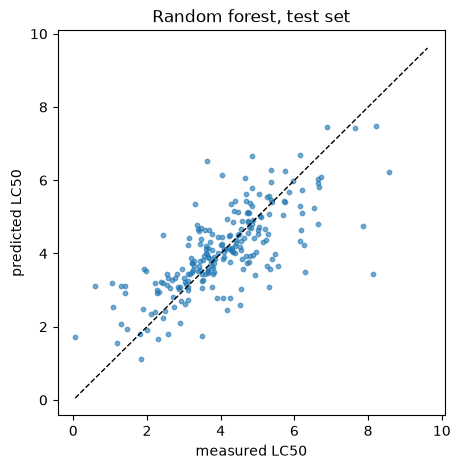

In [21]:
rf = RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1).fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print(f"RF test RMSE = {root_mean_squared_error(y_test, pred_rf):.3f}   R2 = {r2_score(y_test, pred_rf):.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_rf, s=10, alpha=0.6)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "k--", lw=1)
plt.xlabel("measured LC50"); plt.ylabel("predicted LC50"); plt.title("Random forest, test set");

❓ Look at the scatter plot: which chemicals are badly predicted? Is the model better in the middle
or at the extremes?

**Answer.** The predictions are "shrunk" towards the mean: very toxic chemicals are under-predicted
and very non-toxic ones over-predicted. Averaging models (RF, kNN) can never predict outside the
range of their training targets. The most toxic chemicals - the ones a regulator cares about -
are often those with a specific mode of action that six descriptors cannot capture.

Would **more data** help? A **learning curve** trains each model on bigger and bigger subsets and
measures the error on the training data and on held-out data.

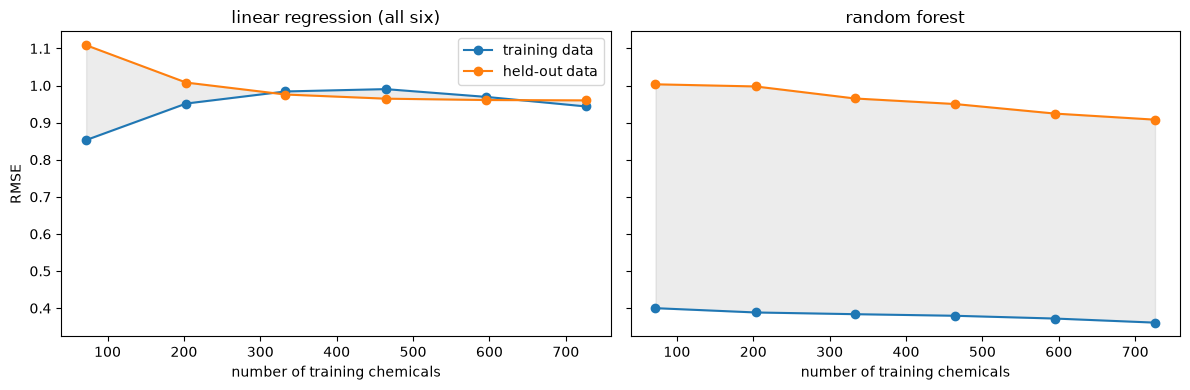

In [22]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, model) in zip(axes, {
        "linear regression (all six)": LinearRegression(),
        "random forest": RandomForestRegressor(n_estimators=100, random_state=RNG, n_jobs=-1)}.items()):
    sizes, tr, te = learning_curve(model, X, y, cv=cv, train_sizes=np.linspace(0.1, 1, 6),
                                   scoring="neg_root_mean_squared_error")
    ax.plot(sizes, -tr.mean(axis=1), "o-", label="training data")
    ax.plot(sizes, -te.mean(axis=1), "o-", label="held-out data")
    ax.fill_between(sizes, -tr.mean(axis=1), -te.mean(axis=1), alpha=0.15, color="grey")
    ax.set_title(name); ax.set_xlabel("number of training chemicals")
axes[0].set_ylabel("RMSE"); axes[0].legend()
plt.tight_layout()

❓ For which model would testing more chemicals on fish be worth the money?

**Answer.** For the **linear model** the two curves have already met (RMSE ≈ 0.96 on both) after
a few hundred chemicals. It is limited by its own simplicity (high **bias**), and more data will not
help. The **random forest** fits its training data much better than new data (≈ 0.36 vs ≈ 0.91:
high **variance**), and its held-out error is still going down at 726 chemicals. More data would
probably still improve it. The shaded gap is how much the model has memorised.

### Playground: overfitting you can see

Six descriptors are hard to picture. Let us go down to **one dimension** with a toy problem where we
*know* the true curve: 20 noisy "measurements" of a dose-response-like curve. We fit polynomials
of increasing **degree** (degree 1 = straight line, degree 15 = very flexible curve), optionally with
a **ridge** penalty `alpha` on large coefficients (the same idea as `alpha` in the neural networks
of session 2).

`poly_playground()` draws two panels:
* **left**: the data, the true curve and the fitted polynomial. The faint red curves are the same
  model fitted on 20 *other* random samples of the same size: how much the fit changes from one
  dataset to the next is the **variance** of the model.
* **right**: training and test error for every degree 0-20, with the current degree marked. The
  dotted line is the noise level: no model can do better than that on new data.

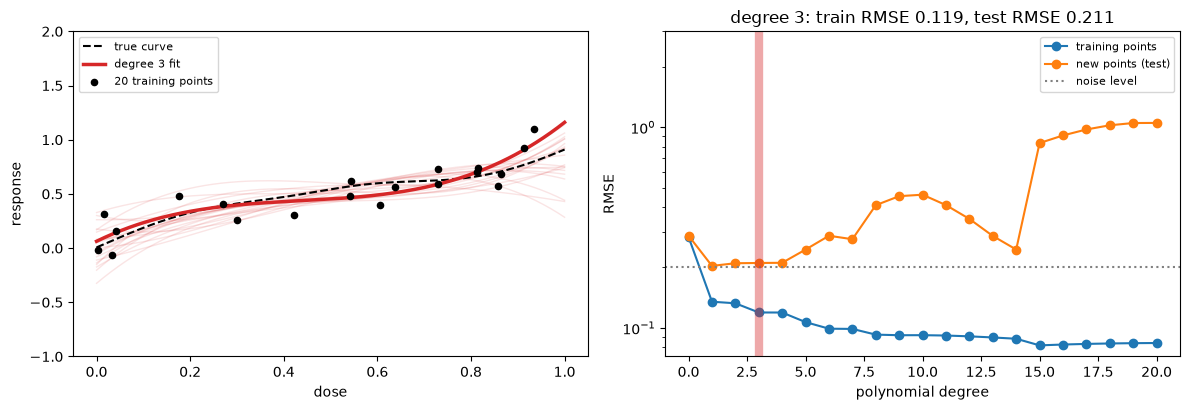

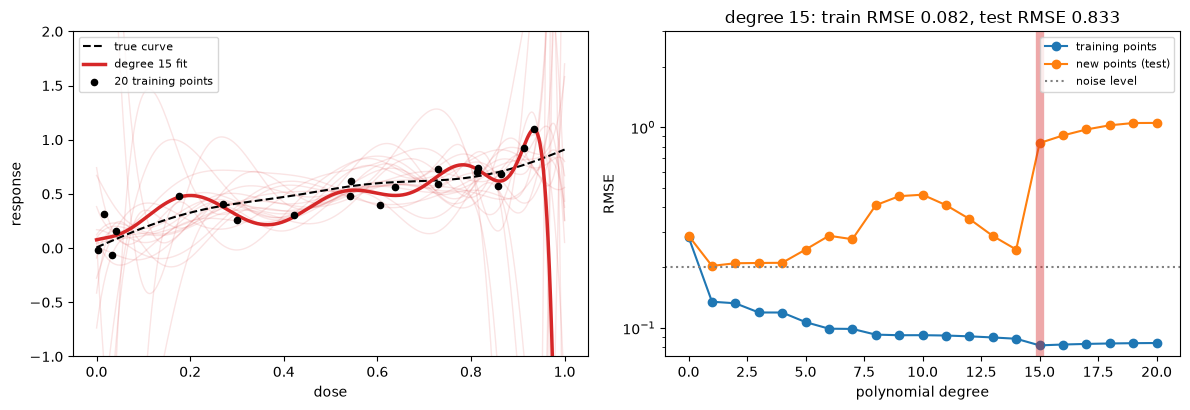

In [23]:
def true_curve(x):
    """The 'truth' we pretend not to know: a smooth dose-response-like curve."""
    return 1 / (1 + np.exp(-10 * (x - 0.5))) + 0.3 * np.sin(6 * x)

def make_toy(n, noise, seed):
    """n noisy measurements of true_curve at random x in [0, 1]."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 1, n))
    return x, true_curve(x) + rng.normal(0, noise, n)

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

def poly_model(degree, alpha):
    reg = Ridge(alpha=alpha) if alpha > 0 else LinearRegression()
    return make_pipeline(PolynomialFeatures(degree), StandardScaler(), reg)

def poly_playground(degree=3, n_train=20, noise=0.2, alpha=0.0, seed=0, show_variance=True):
    x_tr, y_tr = make_toy(n_train, noise, seed)
    x_te, y_te = make_toy(500, noise, seed + 1000)            # fresh data from the same "experiment"
    grid = np.linspace(0, 1, 400)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

    if show_variance:
        for s in range(1, 21):
            xs, ys = make_toy(n_train, noise, 100 * seed + s)
            ax1.plot(grid, poly_model(degree, alpha).fit(xs[:, None], ys).predict(grid[:, None]),
                     color="tab:red", alpha=0.12, lw=1)
    model = poly_model(degree, alpha).fit(x_tr[:, None], y_tr)
    ax1.plot(grid, true_curve(grid), "k--", lw=1.5, label="true curve")
    ax1.plot(grid, model.predict(grid[:, None]), color="tab:red", lw=2.5, label=f"degree {degree} fit")
    ax1.scatter(x_tr, y_tr, color="k", s=20, zorder=3, label=f"{n_train} training points")
    ax1.set_ylim(-1, 2); ax1.set_xlabel("dose"); ax1.set_ylabel("response"); ax1.legend(fontsize=8, loc="upper left")

    rmse = lambda m, x, y: np.sqrt(np.mean((m.predict(x[:, None]) - y) ** 2))
    degrees = range(0, 21)
    tr, te = [], []
    for d in degrees:
        m = poly_model(d, alpha).fit(x_tr[:, None], y_tr)
        tr.append(rmse(m, x_tr, y_tr)); te.append(rmse(m, x_te, y_te))
    ax2.plot(degrees, tr, "o-", label="training points")
    ax2.plot(degrees, te, "o-", label="new points (test)")
    ax2.axhline(noise, color="grey", ls=":", label="noise level")
    ax2.axvline(degree, color="tab:red", alpha=0.4, lw=6)
    ax2.set_yscale("log"); ax2.set_ylim(top=3); ax2.set_xlabel("polynomial degree"); ax2.set_ylabel("RMSE")
    ax2.set_title(f"degree {degree}: train RMSE {tr[degree]:.3f}, test RMSE {te[degree]:.3f}")
    ax2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

poly_playground(degree=3)
poly_playground(degree=15)

*Sliders:* in Jupyter or Colab with `ipywidgets` installed, the next cell shows sliders and redraws the figure when you release one. Without `ipywidgets`, just call the function with other values.

In [24]:
try:
    from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Checkbox
    interact(poly_playground,
             degree=IntSlider(value=3, min=0, max=20, continuous_update=False),
             n_train=IntSlider(value=20, min=8, max=300, step=4, continuous_update=False),
             noise=FloatSlider(value=0.2, min=0.0, max=0.8, step=0.05, continuous_update=False),
             alpha=FloatLogSlider(value=1e-8, base=10, min=-8, max=2, continuous_update=False),
             seed=IntSlider(value=0, min=0, max=20, continuous_update=False),
             show_variance=Checkbox(value=True))
except ImportError:
    print("ipywidgets is not installed: call poly_playground(degree=..., n_train=..., noise=..., alpha=...) instead")

interactive(children=(IntSlider(value=3, continuous_update=False, description='degree', max=20), IntSlider(val…

✏️ **Exercise 5.3.** Play with the parameters and answer:
1. With 20 points, which degrees **underfit** and which **overfit**? Look at both panels and at
   the faint red curves.
2. Keep degree 15 and give it more data (`n_train=60`, then `200`). What happens to the faint curves
   and to the gap between training and test error?
3. Keep degree 15 and 20 points, and add regularisation (`alpha=1e-4`, `1e-2`, `1`). Which value
   works best? What happens with `alpha=100`?
4. Change `noise` to 0.05, then 0.5. Does the best degree change?

**Answer.**
1. Degrees 0-2 **underfit**: the fit misses the S shape, and training and test errors are both high
   and close together (high **bias**). Degree 3 to about 8 follows the true curve. From about degree
   12 the fit wiggles through the training points: training error keeps falling, test error shoots up,
   and the faint curves fan out wildly, especially at the edges (high **variance**). A different
   sample of 20 points would give a completely different model. That is what overfitting means.
2. More data tames the flexible model: with 200 points the degree-15 fit hugs the true curve, the faint
   curves collapse onto it, and test error comes down to the noise level. Overfitting is a property of
   the model *and* of the amount of data.
3. A small penalty (≈ `1e-4` to `1e-2`) removes most of the wiggles while keeping the shape. With
   `alpha=100` the penalty dominates and the curve flattens towards the mean: we are back to underfitting.
   Regularisation lets us use a flexible model and turn its flexibility down.
4. With little noise, high degrees do well because the points themselves describe the curve. With a lot
   of noise even moderate degrees start fitting noise, and the best degree drops. More noise means
   prefer simpler models.

## Part 6 - What did the model learn?

**Permutation importance**: shuffle one descriptor in the test set and measure how much the score
drops. If the model relies on that descriptor, scrambling it hurts.

NdssC     0.014
CIC0      0.026
NdsCH     0.088
GATS1i    0.100
SM1_Dz    0.238
MLOGP     0.427
dtype: float64


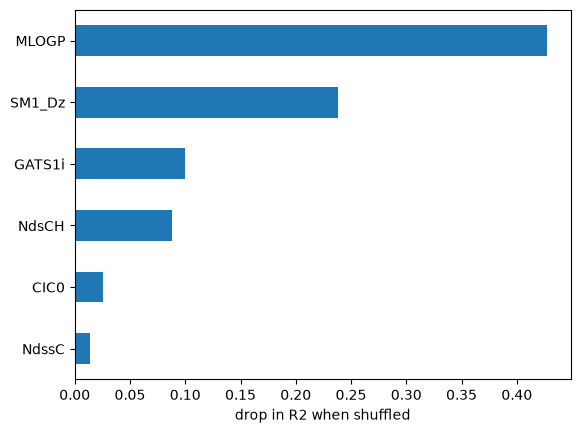

In [25]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RNG, scoring="r2")
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
print(importance)
importance.plot.barh()
plt.xlabel("drop in R2 when shuffled");

❓ Does the random forest agree with the correlation analysis of Part 2?

**Answer.** Yes: `MLOGP` is by far the most important, followed by `SM1_Dz` and `GATS1i`. The
data mining (correlations) and the model tell the same biological story: lipophilicity first.

## Summary

* **Look at the data first**: distributions, correlations, a PCA map. Most of the story
  (lipophilicity drives baseline toxicity) was visible before any model.
* Always compare to a **baseline** and evaluate on **unseen data**; prefer cross-validation.
* Non-linear models (kNN, RF) gain a little over linear regression (R² ≈ 0.56 → 0.60);
  distance-based models need **scaled** inputs.
* Fitting = **minimising a loss**. Linear regression does it with a formula, neural networks by
  gradient descent, walking down the loss landscape.
* One train/test split is a noisy estimate (R² 0.44 here vs ≈ 0.57 on average); cross-validation
  uses every chemical once as test data.
* Training error always goes down with model flexibility; held-out error does not. The gap between
  them (kNN with small *k*, random forest) is **overfitting**.

## Part 7 - Your turn: water fleas (homework)

`load_aquatic()` gives a second dataset: **546 chemicals** tested on the water flea
*Daphnia magna* (48 h LC50, same units), with 8 descriptors, among them `MLOGP` again and `TPSA`
(polar surface area), `nN` (number of nitrogens), `H050` (hydrogens attached to heteroatoms).

✏️ Repeat the analysis in a few cells: correlations with LC50, cross-validated R² of linear
regression, scaled kNN and random forest. Is lipophilicity still the top predictor?
Is this dataset easier or harder than the fish one? Does scaling matter more or less?

In [26]:
aq = load_aquatic()
Xa, ya = aq.drop(columns="LC50"), aq["LC50"]
print(aq.corr()["LC50"].drop("LC50").sort_values(ascending=False), "\n")

for name, model in {
    "linear":        LinearRegression(),
    "kNN (scaled)":  make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "kNN (raw)":     KNeighborsRegressor(n_neighbors=10),
    "random forest": RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1),
}.items():
    print(f"{name:14s} R2 = {cross_val_score(model, Xa, ya, cv=cv, scoring='r2').mean():.3f}")

MLOGP     0.536
RDCHI     0.391
TPSA      0.038
C040      0.024
nN       -0.070
SAacc    -0.098
H050     -0.189
GATS1p   -0.312
Name: LC50, dtype: float64 

linear         R2 = 0.460
kNN (scaled)   R2 = 0.482


kNN (raw)      R2 = 0.242


random forest  R2 = 0.514


**Answer.** `MLOGP` is again the most correlated descriptor (r ≈ 0.54). The Daphnia set is harder
(R² ≈ 0.46 linear, ≈ 0.51 RF). Scaling matters much more here: unscaled kNN collapses (≈ 0.48 → 0.24)
because `TPSA` and `SAacc` have values in the hundreds and dominate the distances.